PURCHASE BEHAVIOR PREDICTION
Dataset Shape: (1000, 36)

Purchase Intent Classes:
Purchase_Intent
Need-based     256
Wants-based    249
Impulsive      248
Planned        247
Name: count, dtype: int64

Numerical Features:
['Age', 'Frequency_of_Purchase', 'Brand_Loyalty', 'Product_Rating', 'Time_Spent_on_Product_Research(hours)', 'Return_Rate', 'Customer_Satisfaction', 'Time_to_Decision', 'Purchase_Year', 'Purchase_Month', 'Purchase_Day', 'Purchase_DayOfWeek', 'Purchase_Hour', 'Spending_per_Purchase_Frequency', 'Engagement_Score', 'Research_to_Decision_Ratio', 'Customer_Segment']

Categorical Features:
['Gender', 'Income_Level', 'Marital_Status', 'Education_Level', 'Occupation', 'Location', 'Purchase_Category', 'Purchase_Channel', 'Social_Media_Influence', 'Discount_Sensitivity', 'Engagement_with_Ads', 'Device_Used_for_Shopping', 'Payment_Method', 'Shipping_Preference']

Training Samples: 800
Testing Samples: 200

------------------------------------------------------------
Logistic Regre

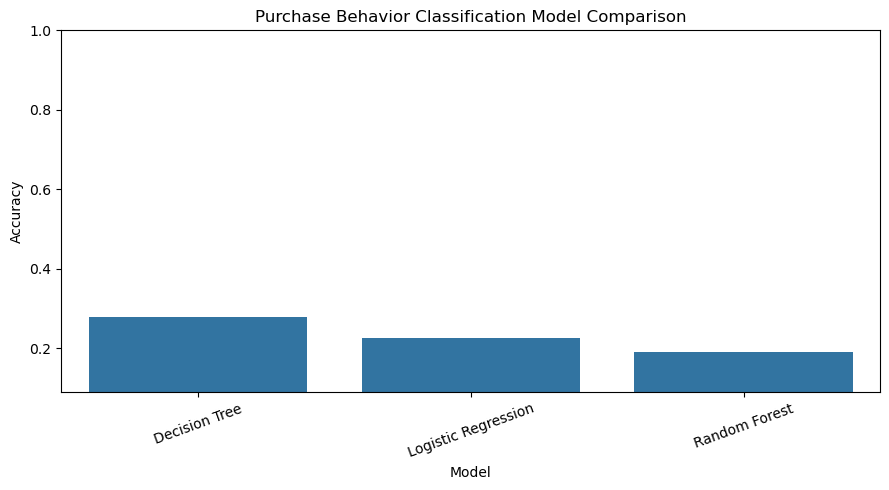


Best Classification Model: Decision Tree
Best Accuracy: 0.28


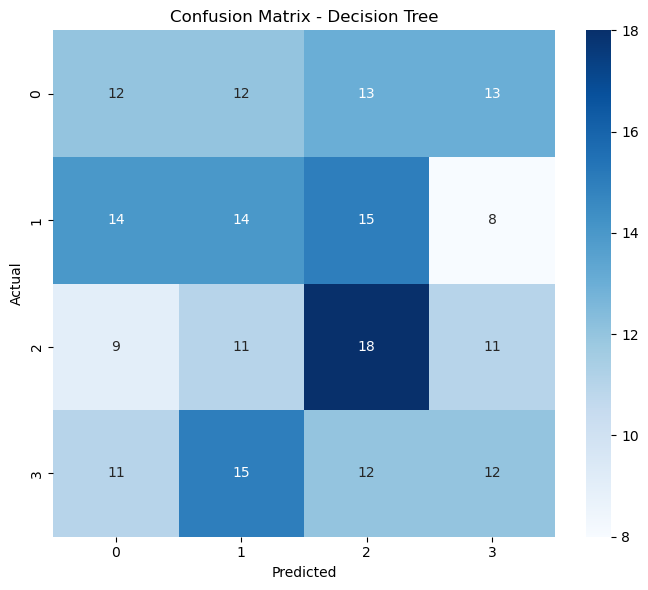


Final Classification Report:
              precision    recall  f1-score   support

   Impulsive       0.26      0.24      0.25        50
  Need-based       0.27      0.27      0.27        51
     Planned       0.31      0.37      0.34        49
 Wants-based       0.27      0.24      0.26        50

    accuracy                           0.28       200
   macro avg       0.28      0.28      0.28       200
weighted avg       0.28      0.28      0.28       200


Purchase behavior model saved to: ../models/purchase_prediction.pkl

PURCHASE BEHAVIOR PREDICTION COMPLETED


In [1]:
# ============================================================
# STEP 7: PURCHASE BEHAVIOR PREDICTION
# CLASSIFICATION USING PURCHASE_INTENT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Load dataset
# ------------------------------------------------------------

df = pd.read_csv(
    "../data/processed/feature_engineered_data.csv"
)

print("=" * 60)
print("PURCHASE BEHAVIOR PREDICTION")
print("=" * 60)

print("Dataset Shape:", df.shape)


# ------------------------------------------------------------
# 2. Target variable
# ------------------------------------------------------------

target = "Purchase_Intent"

print("\nPurchase Intent Classes:")
print(df[target].value_counts())


# ------------------------------------------------------------
# 3. Remove columns that should not be used
# ------------------------------------------------------------

drop_columns = [
    target,
    "Purchase_Amount",
    "Time_of_Purchase"
]

X = df.drop(
    columns=drop_columns,
    errors="ignore"
)

y = df[target]


# ------------------------------------------------------------
# 4. Separate numerical and categorical features
# ------------------------------------------------------------

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


# ------------------------------------------------------------
# 5. Numerical preprocessing
# ------------------------------------------------------------

numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# ------------------------------------------------------------
# 6. Categorical preprocessing
# ------------------------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# ------------------------------------------------------------
# 7. Combine preprocessing
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_pipeline,
            numerical_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)


# ------------------------------------------------------------
# 8. Train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])


# ------------------------------------------------------------
# 9. Classification models
# ------------------------------------------------------------

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}


# ------------------------------------------------------------
# 10. Train and evaluate models
# ------------------------------------------------------------

results = {}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

    pipeline.fit(
        X_train,
        y_train
    )

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    results[name] = accuracy
    trained_models[name] = pipeline

    print("\n" + "-" * 60)
    print(name)
    print("-" * 60)

    print(
        "Accuracy:",
        round(accuracy, 4)
    )

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred
        )
    )


# ------------------------------------------------------------
# 11. Compare models
# ------------------------------------------------------------

results_df = pd.DataFrame(
    list(results.items()),
    columns=[
        "Model",
        "Accuracy"
    ]
)

results_df = results_df.sort_values(
    "Accuracy",
    ascending=False
)

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(results_df)


# ------------------------------------------------------------
# 12. Plot model comparison
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Purchase Behavior Classification Model Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.ylim(
    max(0, results_df["Accuracy"].min() - 0.10),
    1.0
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. Select best model
# ------------------------------------------------------------

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[
    best_model_name
]

print(
    "\nBest Classification Model:",
    best_model_name
)

print(
    "Best Accuracy:",
    round(
        results[best_model_name],
        4
    )
)


# ------------------------------------------------------------
# 14. Confusion Matrix
# ------------------------------------------------------------

best_predictions = best_model.predict(
    X_test
)

cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Confusion Matrix - " +
    best_model_name
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 15. Final classification report
# ------------------------------------------------------------

print("\nFinal Classification Report:")

print(
    classification_report(
        y_test,
        best_predictions
    )
)


# ------------------------------------------------------------
# 16. Save best model
# ------------------------------------------------------------

model_path = (
    "../models/purchase_prediction.pkl"
)

joblib.dump(
    best_model,
    model_path
)

print(
    "\nPurchase behavior model saved to:",
    model_path
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PURCHASE BEHAVIOR PREDICTION COMPLETED")
print("=" * 60)